In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("Medicine_Details.csv")

In [ ]:
print("Shape:", df.shape)
print(df.columns.tolist())
print(df.info())
print(df.head())

Shape: (11825, 9)
['Medicine Name', 'Composition', 'Uses', 'Side_effects', 'Image URL', 'Manufacturer', 'Excellent Review %', 'Average Review %', 'Poor Review %']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11825 entries, 0 to 11824
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Medicine Name       11825 non-null  object
 1   Composition         11825 non-null  object
 2   Uses                11825 non-null  object
 3   Side_effects        11825 non-null  object
 4   Image URL           11825 non-null  object
 5   Manufacturer        11825 non-null  object
 6   Excellent Review %  11825 non-null  int64 
 7   Average Review %    11825 non-null  int64 
 8   Poor Review %       11825 non-null  int64 
dtypes: int64(3), object(6)
memory usage: 831.6+ KB
None
              Medicine Name  \
0   Avastin 400mg Injection   
1  Augmentin 625 Duo Tablet   
2       Azithral 500 Tablet   
3          Ascoril L

In [ ]:
print(df.isna().sum())
print(df.duplicated().sum())
print(df["Medicine Name"].duplicated().sum())

Medicine Name         0
Composition           0
Uses                  0
Side_effects          0
Image URL             0
Manufacturer          0
Excellent Review %    0
Average Review %      0
Poor Review %         0
dtype: int64
84
327


In [ ]:
print(df.nunique())

Medicine Name         11498
Composition            3358
Uses                    712
Side_effects           1512
Image URL             11740
Manufacturer            759
Excellent Review %       85
Average Review %         79
Poor Review %            81
dtype: int64


In [ ]:
for c in ["Medicine Name", "Composition", "Uses", "Side_effects"]:
    print(c, "-> average length:", df[c].str.len().mean().round(1))

Medicine Name -> average length: 19.2
Composition -> average length: 33.1
Uses -> average length: 45.3
Side_effects -> average length: 107.4


In [ ]:
print(df[["Excellent Review %", "Average Review %", "Poor Review %"]].describe())

       Excellent Review %  Average Review %  Poor Review %
count        11825.000000      11825.000000   11825.000000
mean            38.516025         35.756364      25.727611
std             25.225343         18.268134      23.991985
min              0.000000          0.000000       0.000000
25%             22.000000         27.000000       0.000000
50%             34.000000         35.000000      22.000000
75%             51.000000         47.000000      35.000000
max            100.000000         88.000000     100.000000


In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

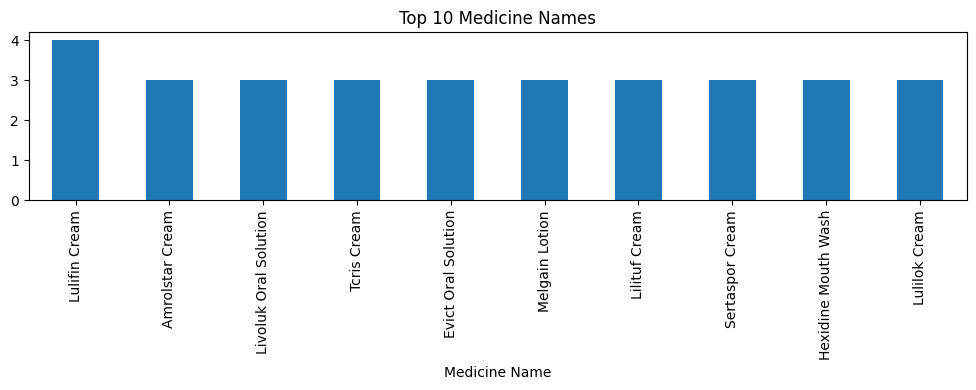

In [ ]:
df["Medicine Name"].value_counts().head(10).plot(kind="bar", figsize=(10, 4))
plt.title("Top 10 Medicine Names"); plt.tight_layout(); plt.show()

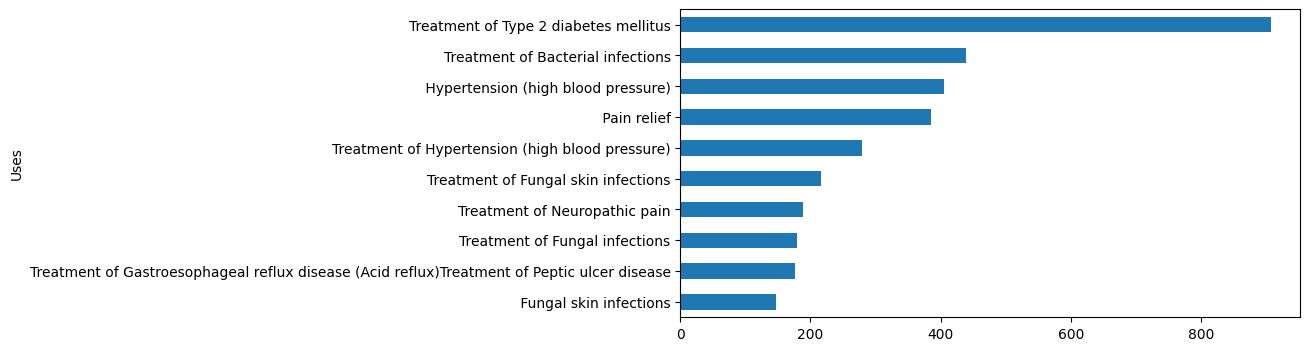

In [ ]:
df["Uses"].value_counts().head(10).plot(kind="barh", figsize=(8, 4))
plt.gca().invert_yaxis()

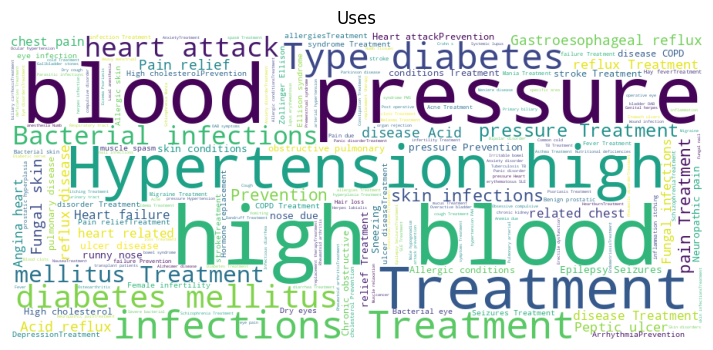

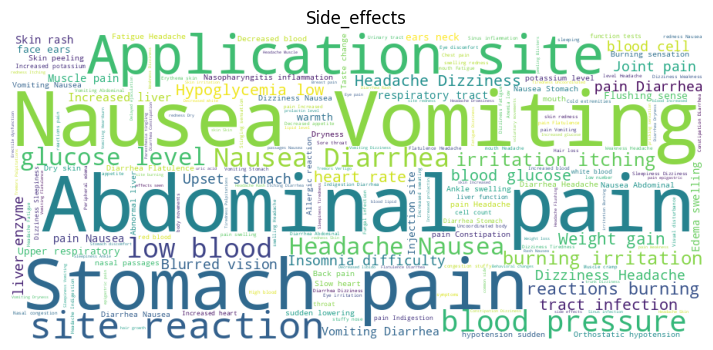

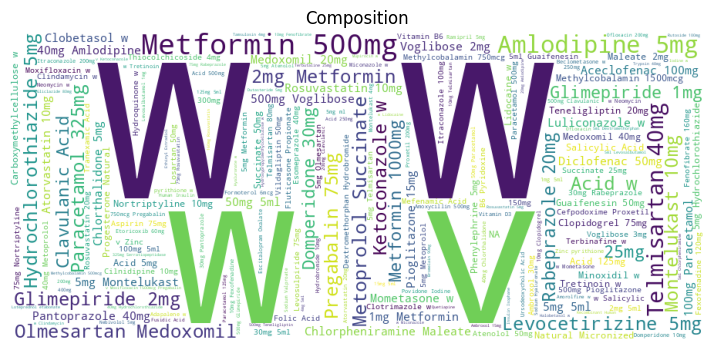

In [ ]:
for col in ["Uses", "Side_effects", "Composition"]:
    wc = WordCloud(width=900, height=400, background_color="white").generate(" ".join(df[col]))
    plt.figure(figsize=(10, 4)); plt.imshow(wc); plt.axis("off"); plt.title(col); plt.show()

**Data Cleaning**

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords"); nltk.download("wordnet"); nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [ ]:
def clean_text(text):
    text = str(text).lower()

In [ ]:
def clean_text(text):
    text = str(text).lower()

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\W", " ", text)

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\W", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+[a-z]\s+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words]
    return " ".join(tokens)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
print(clean_text("Treatment of Bacterial infections (Type-2)!"))

treatment bacterial infection type


In [ ]:
df["Processed_Uses"] = df["Uses"].apply(clean_text)

In [ ]:
text = "Treatment of Bacterial infections (Type-2)!"
text = re.sub(r"\W", " ", text)
print(text)

Treatment of Bacterial infections  Type 2  


In [ ]:
df["Num_Components"] = df["Composition"].str.count(r"\+") + 1

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df["Processed_Uses"])

In [ ]:
def recommend_tfidf(query, top_n=5):
    q = clean_text(query)
    q_vec = tfidf.transform([q])

imports aur TF-IDF matrix

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df["Processed_Uses"])
print(tfidf_matrix.shape)

(11741, 680)


In [ ]:
def recommend_tfidf(query, top_n=5):
    q = clean_text(query)
    q_vec = tfidf.transform([q])
    sims = cosine_similarity(q_vec, tfidf_matrix).ravel()
    idx = sims.argsort()[::-1][:top_n]
    out = df.loc[idx, ["Medicine Name", "Uses", "Composition"]].copy()
    out["Similarity"] = sims[idx].round(3)
    return out

Function ko call karein

In [ ]:
recommend_tfidf("treatment of high blood pressure")

,Medicine Name,Uses,Composition,Similarity
3327,Gloritel M 40 Tablet,Treatment of Hypertension (high blood pressure),Telmisartan (40mg) + Metoprolol Succinate (25mg),0.871
18,Arkamin Tablet,Treatment of Hypertension (high blood pressure),Clonidine (100mcg),0.871
3329,Gloritel AM 40 Tablet,Treatment of Hypertension (high blood pressure),Telmisartan (40mg) + Amlodipine (5mg),0.871
10210,Tetan-AM Tablet,Treatment of Hypertension (high blood pressure),Telmisartan (40mg) + Amlodipine (5mg),0.871
10208,Telminorm AM 40/5 Tablet,Treatment of Hypertension (high blood pressure),Telmisartan (40mg) + Amlodipine (5mg),0.871


**BERT model load and embedding**

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = model.encode(df["Processed_Uses"].tolist(), show_progress_bar=True)
print(embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/367 [00:00<?, ?it/s]

(11741, 384)


In [ ]:
def recommend_bert(query, top_n=5):
    q = clean_text(query)
    q_emb = model.encode([q])
    sims = cosine_similarity(q_emb, embeddings).ravel()
    idx = sims.argsort()[::-1][:top_n]
    out = df.loc[idx, ["Medicine Name", "Uses", "Composition"]].copy()
    out["Similarity"] = sims[idx].round(3)
    return out

In [ ]:
for q in ["treatment of high blood pressure",
          "medicine for sugar problem",
          "stomach infection"]:
    print("=" * 60)
    print("QUERY:", q)
    print("\n--- TF-IDF ---")
    print(recommend_tfidf(q)[["Medicine Name", "Uses", "Similarity"]])
    print("\n--- BERT ---")
    print(recommend_bert(q)[["Medicine Name", "Uses", "Similarity"]])

QUERY: treatment of high blood pressure

--- TF-IDF ---
                  Medicine Name  \
3327      Gloritel M  40 Tablet   
18               Arkamin Tablet   
3329     Gloritel AM  40 Tablet   
10210           Tetan-AM Tablet   
10208  Telminorm AM 40/5 Tablet   

                                                  Uses  Similarity  
3327   Treatment of Hypertension (high blood pressure)       0.871  
18     Treatment of Hypertension (high blood pressure)       0.871  
3329   Treatment of Hypertension (high blood pressure)       0.871  
10210  Treatment of Hypertension (high blood pressure)       0.871  
10208  Treatment of Hypertension (high blood pressure)       0.871  

--- BERT ---
                          Medicine Name  \
10922  Vinicor-AM 25/5 Tablet Tablet PR   
8316                    Repace H Tablet   
10879         Vinicor-AM 50/5 Tablet PR   
10899                 Venpres-AM Tablet   
7045                   Omnitan H Tablet   

                                              

In [ ]:
import random
random.seed(42)

def make_synthetic_query(uses_text):
    words = clean_text(uses_text).split()
    if len(words) > 3:
        k = random.randint(2, len(words))
        words = random.sample(words, k)
    return " ".join(words)

sample = df.sample(1000, random_state=42).copy()
sample["query"] = sample["Uses"].apply(make_synthetic_query)
sample["true_uses"] = sample["Processed_Uses"]

print(sample[["Uses", "query", "true_uses"]].head(10))

                                                  Uses  \
9722                                     Schizophrenia   
1399                               Treatment of Asthma   
2184                Hypertension (high blood pressure)   
3528             Treatment of Nutritional deficiencies   
2935             Treatment of Type 2 diabetes mellitus   
4977               Treatment of Fungal skin infections   
5130         Treatment of InsomniaTreatment of Jet lag   
4793                                           Melasma   
10407                            Treatment of Bleeding   
5362   Prevention of Angina (heart-related chest pain)   

                                  query  \
9722                      schizophrenia   
1399                   treatment asthma   
2184   hypertension pressure high blood   
3528   treatment nutritional deficiency   
2935                      type diabetes   
4977                     treatment skin   
5130                  treatment lag jet   
4793             

In [ ]:
n = 300
test = sample.head(n).reset_index(drop=True)
q_clean = test["query"].apply(clean_text).tolist()

sims_tfidf = cosine_similarity(tfidf.transform(q_clean), tfidf_matrix)
sims_bert = cosine_similarity(model.encode(q_clean), embeddings)

true_uses = test["true_uses"].values
all_uses = df["Processed_Uses"].values

print(sims_tfidf.shape, sims_bert.shape)

(300, 11741) (300, 11741)


In [ ]:
def topk_metrics(sims, k=5):
    top1, pk = [], []
    for i in range(len(sims)):
        idx = np.argsort(-sims[i])[:k]
        correct = (all_uses[idx] == true_uses[i])
        top1.append(correct[0])
        pk.append(correct.mean())
    return np.mean(top1), np.mean(pk)

for name, s in [("TF-IDF", sims_tfidf), ("BERT", sims_bert)]:
    t1, p5 = topk_metrics(s)
    print(f"{name}: Top-1 accuracy = {t1:.3f} | Precision@5 = {p5:.3f}")

TF-IDF: Top-1 accuracy = 0.850 | Precision@5 = 0.836
BERT: Top-1 accuracy = 0.753 | Precision@5 = 0.750


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = (all_uses[None, :] == true_uses[:, None]).ravel()

def threshold_metrics(sims, threshold):
    y_pred = (sims >= threshold).ravel()
    return (accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, zero_division=0),
            recall_score(y_true, y_pred, zero_division=0),
            f1_score(y_true, y_pred, zero_division=0))

rows = []
for name, s in [("TF-IDF", sims_tfidf), ("BERT", sims_bert)]:
    for t in [0.2, 0.3, 0.4, 0.5]:
        a, p, r, f = threshold_metrics(s, t)
        rows.append([name, t, a, p, r, f])

results = pd.DataFrame(rows, columns=["Model", "Threshold", "Accuracy", "Precision", "Recall", "F1"])
print(results.round(3).to_string(index=False))

 Model  Threshold  Accuracy  Precision  Recall    F1
TF-IDF        0.2     0.951      0.231   1.000 0.375
TF-IDF        0.3     0.967      0.309   1.000 0.473
TF-IDF        0.4     0.976      0.385   1.000 0.556
TF-IDF        0.5     0.984      0.475   0.994 0.643
  BERT        0.2     0.580      0.034   1.000 0.066
  BERT        0.3     0.791      0.066   1.000 0.125
  BERT        0.4     0.912      0.142   0.982 0.248
  BERT        0.5     0.954      0.236   0.928 0.376


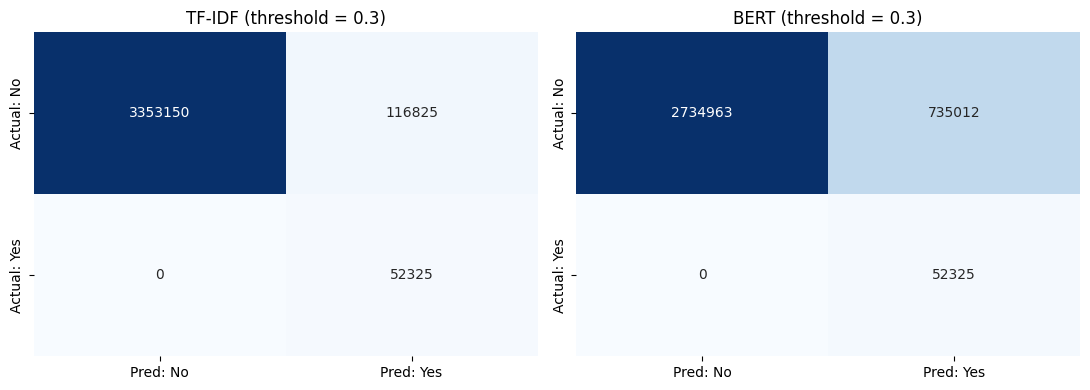

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, s) in zip(axes, [("TF-IDF", sims_tfidf), ("BERT", sims_bert)]):
    y_pred = (s >= 0.3).ravel()
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred: No", "Pred: Yes"],
                yticklabels=["Actual: No", "Actual: Yes"])
    ax.set_title(f"{name} (threshold = 0.3)")
plt.tight_layout()
plt.show()

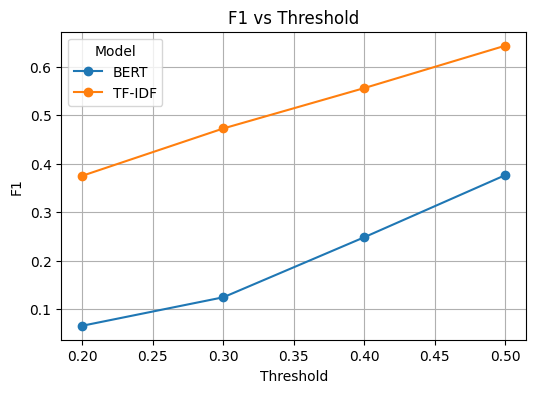

In [ ]:
pivot = results.pivot(index="Threshold", columns="Model", values="F1")
pivot.plot(marker="o", figsize=(6, 4))
plt.title("F1 vs Threshold"); plt.ylabel("F1"); plt.grid(True)
plt.show()